# 04 — Histogram Equalization

Global histogram equalization builds a monotone intensity mapping from the cumulative distribution of an image.

## Learning objectives
- Connect a histogram, probability mass function, and CDF.
- Build and apply a lookup table with NumPy.
- Reproduce OpenCV's CDF-min convention and quantify rounding differences.
- Study discrete limitations, noise amplification, and global mappings.

This notebook runs independently using `skimage.data.camera()`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
np.set_printoptions(precision=4, suppress=True)

## 1. Probability and the cumulative distribution

For $L=256$ levels, $p(k)=h(k)/N$ and

$$F(k)=\sum_{j=0}^k p(j).$$

The continuous probability integral transform motivates $s=(L-1)F(r)$. For discrete images, repeated values cannot be split across output bins by a deterministic pointwise mapping; an exactly uniform histogram is generally impossible.

To use the full output range, OpenCV subtracts the CDF at the first occupied bin. With cumulative **counts** $C(k)$ and first occupied count $C_{min}$:

$$T(k)=\operatorname{round}\left[255\frac{C(k)-C_{min}}{N-C_{min}}\right].$$

Clip negative entries for unused bins to zero and store a uint8 lookup table. For a constant image $N=C_{min}$, preserve the input as an explicit special case. A raw-CDF mapping and this CDF-min mapping are distinct conventions.

In [2]:
image = data.camera()
low_contrast = np.rint(90 + 0.28 * image.astype(float)).astype(np.uint8)

def equalize_u8(array):
    array = np.asarray(array)
    if array.dtype != np.uint8 or array.ndim != 2 or array.size == 0:
        raise ValueError('Expected a nonempty 2D uint8 image')
    counts = np.bincount(array.ravel(), minlength=256)
    cumulative = np.cumsum(counts)
    first = np.flatnonzero(counts)[0]
    cdf_min = cumulative[first]
    if array.size == cdf_min:
        return array.copy(), np.arange(256, dtype=np.uint8)
    table = np.clip(np.rint(255.0 * (cumulative - cdf_min) / (array.size - cdf_min)), 0, 255).astype(np.uint8)
    return table[array], table

equalized, table = equalize_u8(low_contrast)
cv_equalized = cv2.equalizeHist(low_contrast)
difference = equalized.astype(np.int16) - cv_equalized.astype(np.int16)
print('Maximum absolute OpenCV difference (levels):', np.abs(difference).max())
print('Fraction of differing pixels:', np.mean(difference != 0))
assert np.abs(difference).max() <= 1
assert np.all(np.diff(table.astype(int)) >= 0)
assert equalized.dtype == np.uint8 and equalized.shape == image.shape
constant = np.full((12, 12), 87, dtype=np.uint8)
assert np.array_equal(equalize_u8(constant)[0], constant)
assert np.array_equal(cv2.equalizeHist(constant), constant)

Maximum absolute OpenCV difference (levels): 0
Fraction of differing pixels: 0.0


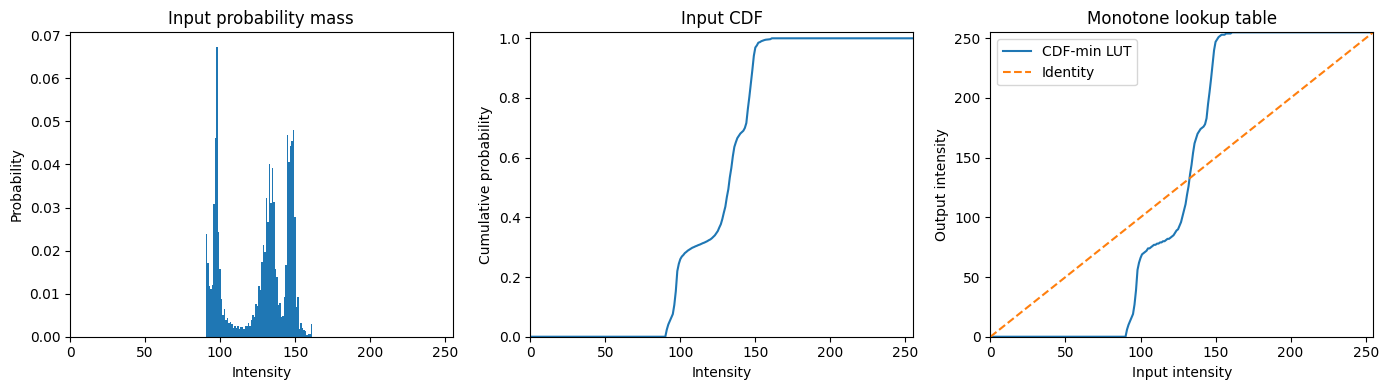

In [3]:
counts = np.bincount(low_contrast.ravel(), minlength=256)
cdf = np.cumsum(counts) / low_contrast.size
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(np.arange(256), counts / low_contrast.size, width=1)
axes[0].set(title='Input probability mass', xlabel='Intensity', ylabel='Probability', xlim=(0, 255))
axes[1].plot(cdf)
axes[1].set(title='Input CDF', xlabel='Intensity', ylabel='Cumulative probability', xlim=(0, 255), ylim=(0, 1.02))
axes[2].plot(table, label='CDF-min LUT')
axes[2].plot([0, 255], [0, 255], '--', label='Identity')
axes[2].set(title='Monotone lookup table', xlabel='Input intensity', ylabel='Output intensity', xlim=(0, 255), ylim=(0, 255))
axes[2].legend()
plt.tight_layout()
plt.show()

## 2. Visualize the transformation

All images use the same 0–255 display range. Histogram gaps after equalization are expected: the compressed input has fewer than 256 distinct levels. Library agreement tests the implementation, not whether equalization is desirable for the scene.

Distinct input/output levels: 72 61


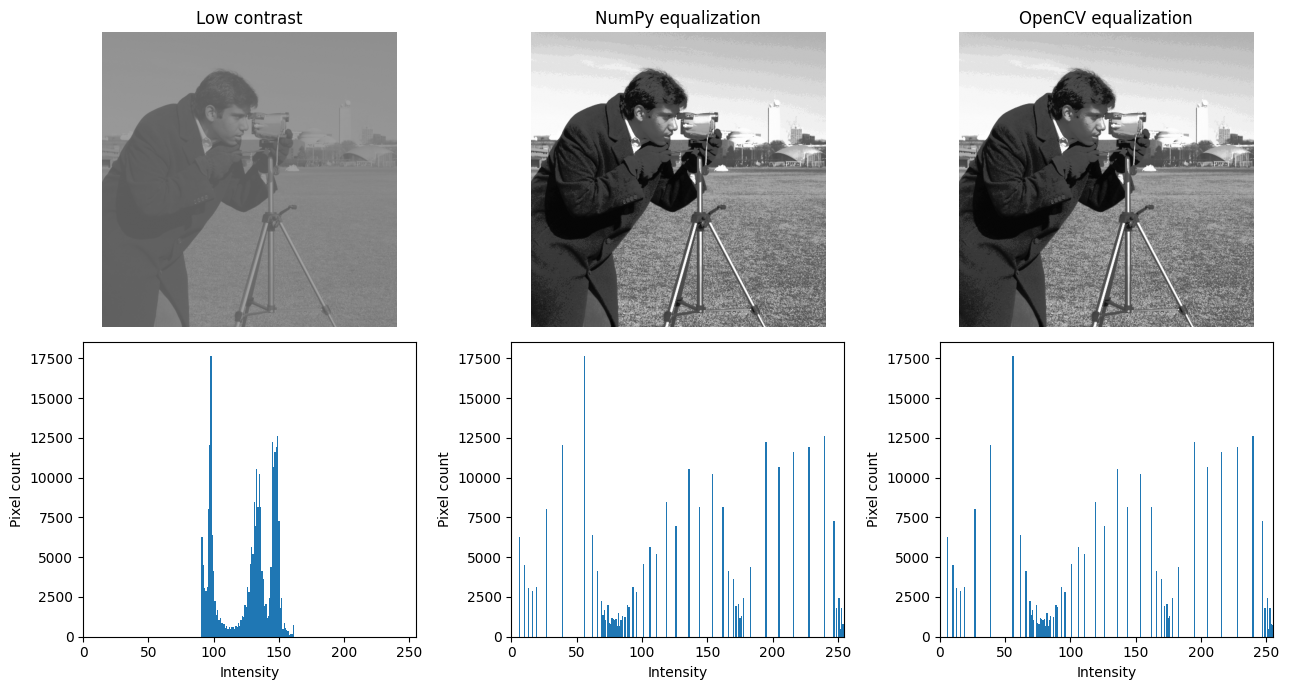

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, (name, arr) in enumerate([('Low contrast', low_contrast), ('NumPy equalization', equalized), ('OpenCV equalization', cv_equalized)]):
    axes[0, col].imshow(arr, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(name)
    axes[0, col].axis('off')
    axes[1, col].bar(np.arange(256), np.bincount(arr.ravel(), minlength=256), width=1)
    axes[1, col].set(xlabel='Intensity', ylabel='Pixel count', xlim=(0, 255))
plt.tight_layout()
plt.show()
print('Distinct input/output levels:', len(np.unique(low_contrast)), len(np.unique(equalized)))

## 3. Compare raw-CDF equalization with scikit-image

`skimage.exposure.equalize_hist` uses the raw normalized CDF and returns floats. With uint8 data its integer bins permit a direct NumPy comparison. It does not implement the CDF-min convention above; the first occupied output level can exceed zero.

First occupied raw-CDF value: 7.62939453125e-06
First occupied CDF-min LUT value: 0


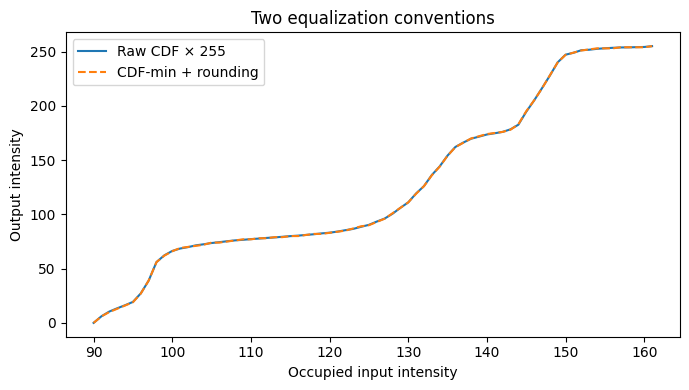

In [5]:
from skimage import exposure

raw_cdf_output = cdf[low_contrast]
sk_output = exposure.equalize_hist(low_contrast)
assert np.allclose(raw_cdf_output, sk_output)
occupied = np.flatnonzero(counts)
print('First occupied raw-CDF value:', cdf[occupied[0]])
print('First occupied CDF-min LUT value:', table[occupied[0]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(occupied, 255 * cdf[occupied], label='Raw CDF × 255')
ax.plot(occupied, table[occupied], '--', label='CDF-min + rounding')
ax.set(xlabel='Occupied input intensity', ylabel='Output intensity', title='Two equalization conventions')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Noise can become visible structure

In a nearly uniform region, small sensor variations can occupy most histogram mass. Equalization may expand those variations across almost the entire display range. The following synthetic noisy patch isolates this effect; it is not a restoration task and no clean details are present to recover.

Input/output patch standard deviation: 2.02610046469743 72.9897180800919


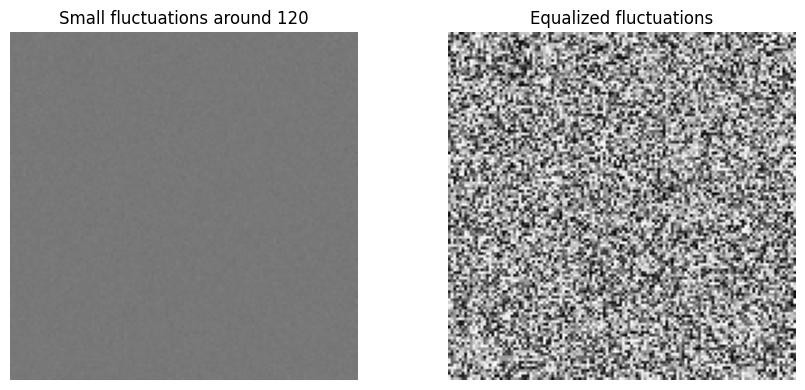

In [6]:
rng = np.random.default_rng(42)
noisy_patch = np.clip(np.rint(120 + rng.normal(0, 2, (128, 128))), 0, 255).astype(np.uint8)
patch_equalized, _ = equalize_u8(noisy_patch)
print('Input/output patch standard deviation:', noisy_patch.std(), patch_equalized.std())
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, arr, name in zip(axes, [noisy_patch, patch_equalized], ['Small fluctuations around 120', 'Equalized fluctuations']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review

A steep segment of the LUT expands nearby input values; a flat segment merges output values. The LUT preserves nondecreasing intensity order but can alter average brightness and the appearance of noise. A single global mapping cannot adapt separately to shadow and highlight neighborhoods. Applying equalization independently to RGB channels can shift colors.

1. Why is the output histogram not exactly flat?
2. Why must CDF arithmetic use a signed or floating dtype before subtraction?
3. How do raw-CDF and CDF-min mappings behave at the first occupied input bin?
4. Why does increased noise visibility not imply additional scene information?
5. Compare equalization to affine contrast stretching: which transform depends on the distribution inside the endpoints?

## Summary and connection

Histogram equalization is a nonlinear, data-dependent point operation. Its probability foundation connects Image Processing to statistical transforms; its global nature motivates local methods such as CLAHE. Computer Vision preprocessing must balance useful detail enhancement against noise and distribution shifts.